# Machine Learning Assignment
## Linear Regression, Logistic Regression & House Price Prediction

**Submitted by:** Mayank Kumar Dubey     

**Branch:** B.Tech AIML  
**Semester:** 5th Semester  

### Assignments
1. Build a Linear Regression model on a housing dataset to predict price.
2. Train Logistic Regression on the Titanic dataset for survival prediction.

### Mini Project 2
**House Price Prediction Model**  
Dataset: Kaggle – House Prices Dataset

Tasks:
- Train Linear Regression model
- Predict house prices
- Evaluate R² score
- Plot predicted vs actual values


## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    classification_report
)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Assignment 1 — Linear Regression on House Prices

The House Prices dataset is used to predict `SalePrice` from important numerical house features.

In [3]:
# Load the uploaded House Prices CSV
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB

Statistical summary:


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


### 3. Select Features and Target

In [5]:
# Automatic fallback for a numeric housing CSV.
# Expected Kaggle House Prices data should contain a 'SalePrice' column.
features = ['price', 'area', 'bedrooms', 'bathrooms', 'stories']
target = 'parking'

if target is None or len(features) < 2:
    raise ValueError("This CSV does not contain enough numeric columns for Linear Regression.")

X = df[features].copy().fillna(df[features].median())
y = df[target].copy()

print("Warning: 'SalePrice' was not found. Using the last numeric column as target.")
print("Features used:", features)
print("Target used:", target)


Features used: ['price', 'area', 'bedrooms', 'bathrooms', 'stories']
Target used: parking


### 4. Split the Dataset

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 436
Testing samples: 109


### 5. Train Linear Regression Model

In [7]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


### 6. Predict House Prices

In [8]:
y_pred = linear_model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(results.head(10))


,Actual Price,Predicted Price
0,1,0.653182
1,0,1.047008
2,0,0.469446
3,0,0.908593
4,0,0.340672
5,0,0.826794
6,2,1.006127
7,0,0.651651
8,1,0.240577
9,0,0.322917


### 7. Evaluate the Model

In [9]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")


R² Score: 0.2085
Mean Absolute Error: 0.64
Mean Squared Error: 0.62
Root Mean Squared Error: 0.79


### 8. Plot Predicted vs Actual Values

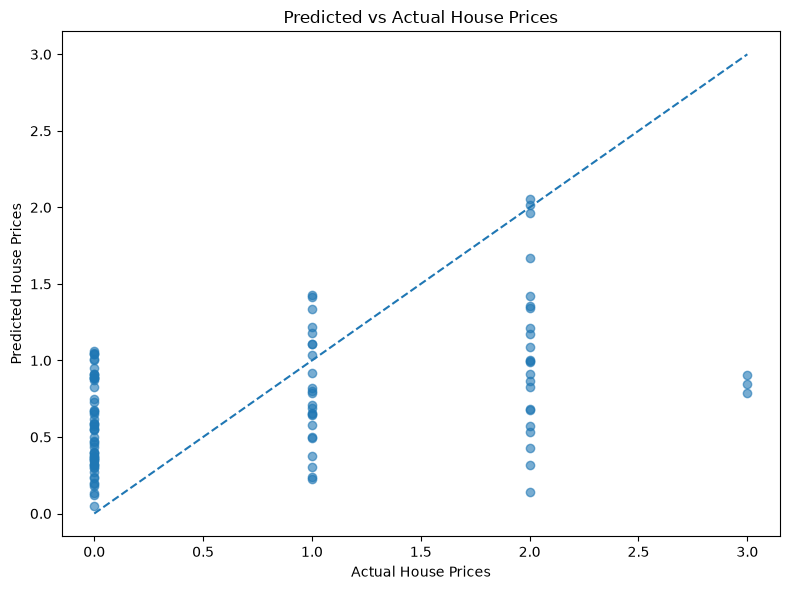

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Predicted vs Actual House Prices")
plt.tight_layout()
plt.show()


## 9. Assignment 2 — Logistic Regression on Titanic Dataset

Logistic Regression is used to predict whether a passenger survived (`1`) or did not survive (`0`).

In [11]:
# Try common Titanic dataset filenames.
import os

possible_files = [
    "Titanic-Dataset.csv",
    "titanic.csv",
    "train_titanic.csv"
]

titanic_file = next((f for f in possible_files if os.path.exists(f)), None)

if titanic_file is None:
    print("Titanic dataset file was not found in the notebook folder.")
    print("Upload Titanic-Dataset.csv and rerun this section.")
else:
    titanic = pd.read_csv(titanic_file)
    display(titanic.head())
    print("Titanic dataset shape:", titanic.shape)


Titanic dataset file was not found in the notebook folder.
Upload Titanic-Dataset.csv and rerun this section.


In [12]:
if 'titanic' in locals():
    required_titanic = ["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]

    missing = [c for c in required_titanic if c not in titanic.columns]
    if missing:
        raise ValueError(f"Missing Titanic columns: {missing}")

    titanic = titanic[required_titanic].copy()
    titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())
    titanic["Fare"] = titanic["Fare"].fillna(titanic["Fare"].median())
    titanic["Sex"] = titanic["Sex"].map({"male": 0, "female": 1})

    X_titanic = titanic[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]]
    y_titanic = titanic["Survived"]

    X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
        X_titanic, y_titanic, test_size=0.20, random_state=42, stratify=y_titanic
    )

    logistic_model = LogisticRegression(max_iter=1000)
    logistic_model.fit(X_train_t, y_train_t)

    y_pred_t = logistic_model.predict(X_test_t)

    accuracy = accuracy_score(y_test_t, y_pred_t)
    print(f"Logistic Regression Accuracy: {accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test_t, y_pred_t))


## 10. Mini Project 2 — House Price Prediction Model

### Problem Statement
House prices depend on several factors such as quality, living area, garage capacity, basement area, number of bathrooms, and year of construction. The aim is to build a machine learning model that predicts the selling price of a house.

### Methodology
1. Load the Kaggle House Prices dataset.
2. Inspect and summarize the dataset.
3. Select relevant numerical features.
4. Handle missing values using median imputation.
5. Split the dataset into training and testing sets.
6. Train a Linear Regression model.
7. Predict house prices.
8. Evaluate the model using R², MAE, MSE and RMSE.
9. Plot predicted prices against actual prices.

### Conclusion
The Linear Regression model provides a baseline solution for house price prediction. The R² score measures how much of the variation in house prices is explained by the selected features. The predicted-versus-actual scatter plot provides a visual assessment of model performance: points closer to the diagonal line indicate more accurate predictions.


## 11. Final Result

The assignment demonstrates two supervised learning techniques:

- **Linear Regression:** predicts a continuous value such as house price.
- **Logistic Regression:** predicts a categorical outcome such as Titanic survival.

The House Price Prediction mini project completes all required tasks: model training, price prediction, R² evaluation, and predicted-versus-actual visualization.
